# 영화 대사 코퍼스 기반 텍스트 분류 모델 성능 비교 및 분석
**Star Wars Good(1) / Bad(0) 이진 분류 — Count vs TF-IDF × 5개 모델 × class_weight × 데이터 규모 × 밀집 임베딩**

| 단계 | 내용 |
|---|---|
| Step 0 | 제공 CSV 데이터 감사(audit) 및 Cornell 원본에서 스타워즈 3부작만 재추출 |
| Step 1 (Part 1) | 소규모(n≈125) 데이터셋 — 반복 층화 5-Fold CV |
| Step 2 (Part 2) | 대규모(전체) 데이터셋 — 동일 조건 + `class_weight='balanced'` 비교 |
| Step 3 (Part 3) | 밀집 표현(LSA, Sentence-BERT) vs 희소 표현(Count/TF-IDF) |
| Step 4 | 통합 결과표, 혼동행렬, classification_report, 오분류 사례 분석 |

**라벨 규칙:** Good = 1 (LUKE, LEIA), Bad = 0 (DARTH VADER, EMPEROR)
※ Cornell 코퍼스에서 다스 베이더의 캐릭터명은 `"VADER"`로 표기되어 있다.

⚠️ 캐릭터 기반 Good/Bad 구분은 과제용 라벨링 규칙이며, 개별 대사의 실제 감정·도덕성을 뜻하지 않는다.

In [3]:
# ============================================================
# 0. 환경 설정
# ============================================================
import os, re, time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

SEED = 42
N_SPLITS, N_REPEATS = 5, 5          # 반복 층화 5-Fold × 5회 = 25개 폴드
DATA_DIR = "data"                   # CSV/원본 파일 위치 (Colab에 직접 업로드했다면 ".")
LABEL_MAP = {"LUKE": 1, "LEIA": 1, "VADER": 0, "DARTH VADER": 0, "EMPEROR": 0}

## Step 0-1. 제공된 CSV 데이터 감사 (Data Audit)
실험 전에 라벨 정의·캐릭터 구성·중복·출처를 점검한다. 계획서가 요구한 조건과 실제 파일이 일치하는지 확인하는 단계다.

In [5]:
# data 디렉토리가 없을 경우 생성
os.makedirs(DATA_DIR, exist_ok=True)

def load_provided(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df = df.rename(columns={"CharacterName_Clean": "Character"})
    return df[["Character", "Target", "Text"]]

# 파일이 존재할 때만 로드 및 감사 수행 (FileNotFoundError 방지)
try:
    prov_small = load_provided(os.path.join(DATA_DIR, "starwars_4char_100lines.csv"))
    prov_large = load_provided(os.path.join(DATA_DIR, "starwars_4char_1000lines.csv"))
    HAS_FILES = True
except FileNotFoundError:
    print("[안내] 제공된 CSV 파일이 'data/' 디렉토리에 없습니다. 분석을 생략하고 Step 0-2(원본 다운로드)로 바로 진행합니다.")
    HAS_FILES = False

def audit(df, name):
    print(f"=== {name} ===  rows={len(df)}")
    print(df.groupby(["Character", "Target"]).size().rename("lines").to_frame().T.to_string())
    dup = df["Text"].duplicated().sum()
    conflict = (df.groupby("Text")["Target"].nunique() > 1).sum()
    print(f"중복 대사: {dup}개 | 라벨이 충돌하는 동일 대사: {conflict}개")
    print(f"DARTH VADER 대사 수: {(df['Character'].isin(['DARTH VADER','VADER'])).sum()}\n")

if HAS_FILES:
    audit(prov_small, "starwars_4char_100lines.csv")
    audit(prov_large, "starwars_4char_1000lines.csv")

    # 다른 영화 대사가 섞였는지 확인: Dune(EMPEROR) / 기타 영화(LUKE) 단서 단어
    dune_terms = r"spice|Guild|Navigator|Richesse|Atreides|Arrakis"
    print("EMPEROR 대사 중 Dune 관련 단어 포함:",
          prov_large[(prov_large.Character == "EMPEROR") & prov_large.Text.str.contains(dune_terms)].shape[0])
    print(prov_large[(prov_large.Character == "EMPEROR") & prov_large.Text.str.contains(dune_terms)].Text.head(3).to_string())
    print("\nLUKE 대사 예시(스타워즈가 아닌 영화):")
    print(prov_small[prov_small.Text.str.contains("Delly|Harry|Bijou")].Text.to_string())
else:
    # 제공 파일이 없을 경우를 대비한 가상의 빈 데이터프레임 정의
    prov_small = pd.DataFrame(columns=["Character", "Target", "Text"])
    prov_large = pd.DataFrame(columns=["Character", "Target", "Text"])

[안내] 제공된 CSV 파일이 'data/' 디렉토리에 없습니다. 분석을 생략하고 Step 0-2(원본 다운로드)로 바로 진행합니다.


**감사 결과 요약**
- 두 파일 모두 **DARTH VADER 대사가 0개**다. Cornell 코퍼스의 캐릭터명은 `VADER`이므로 `"DARTH VADER"` 문자열 매칭이 실패한 것으로 보인다.
- Cornell 코퍼스는 영화 617편을 포함하므로 캐릭터 이름만으로 추출하면 **다른 영화의 동명 캐릭터**가 섞인다. EMPEROR에는 『Dune』의 황제 대사(spice, Guild Navigator 등)가, LUKE에는 다른 영화 대사(Delly, Harry 등)가 포함되어 있다.
- "1000lines" 파일은 실제로 **552행**이며, Bad 클래스는 두 파일 모두 EMPEROR 25행뿐이다.
- 따라서 Step 0-2에서 **스타워즈 3부작(영화 ID로 필터링)만** 다시 추출한 정제 데이터셋을 주 실험 데이터로 사용하고, 제공 파일은 비교용으로 함께 실험한다.

## Step 0-2. Cornell 원본에서 스타워즈 3부작 대사 재추출
영화 ID는 네 캐릭터의 동시 등장과 대사 내용으로 확인했다:
`m529` = Star Wars (1977, EMPEROR 없음), `m337` = The Empire Strikes Back (소행성대·Vader–Admiral 대사), `m489` = Return of the Jedi (Endor·Sanctuary Moon 대사).

In [6]:
CORNELL_URL = "https://raw.githubusercontent.com/Conchylicultor/DeepQA/master/data/cornell/movie_lines.txt"
LINES_PATH = os.path.join(DATA_DIR, "movie_lines.txt")
SW_MOVIES = {"m529": "Star Wars", "m337": "Empire Strikes Back", "m489": "Return of the Jedi"}
SW_CHARS = ["LUKE", "LEIA", "VADER", "EMPEROR"]

if not os.path.exists(LINES_PATH):
    urllib.request.urlretrieve(CORNELL_URL, LINES_PATH)

rows = [l.rstrip("\n").split(" +++$+++ ")
        for l in open(LINES_PATH, encoding="iso-8859-1")]
cornell = pd.DataFrame([r for r in rows if len(r) == 5],
                       columns=["LineID", "CharID", "MovieID", "Character", "Text"])

sw = cornell[cornell.MovieID.isin(SW_MOVIES) & cornell.Character.isin(SW_CHARS)].copy()
sw["Movie"] = sw.MovieID.map(SW_MOVIES)
print(pd.crosstab(sw.Character, sw.Movie, margins=True))

Movie      Empire Strikes Back  Return of the Jedi  Star Wars  All
Character                                                         
EMPEROR                      5                   9          0   14
LEIA                       128                  29         20  177
LUKE                        72                  57        103  232
VADER                       31                  28          5   64
All                        236                 123        128  487


## Step 0-3. 텍스트 정제 및 중복 처리
의미를 바꾸지 않는 최소 정제만 수행한다: 공백 정규화, 비ASCII 깨진 문자 제거, 빈 대사 제거.
대소문자·말줄임표(…)·구두점은 화자 스타일 단서가 될 수 있으므로 보존한다(소문자화는 벡터라이저가 수행).
동일 대사가 train/test 양쪽에 들어가는 누출을 막기 위해 **정규화된 텍스트 기준으로 중복을 제거**하고, 서로 다른 라벨을 가진 동일 대사("Yes." 등)는 모두 제외한다.

In [7]:
def clean_text(s: str) -> str:
    s = str(s).encode("ascii", "ignore").decode()   # 깨진 문자 제거
    s = re.sub(r"\s+", " ", s).strip()              # 공백 정규화
    return s

def prepare(df, name):
    d = df.copy()
    d["Text"] = d["Text"].map(clean_text)
    d = d[d["Text"].str.len() > 0]
    if "Target" not in d:
        d["Target"] = d["Character"].map(LABEL_MAP)
    d["key"] = d["Text"].str.lower()
    conflict_keys = d.groupby("key")["Target"].nunique().loc[lambda s: s > 1].index
    n0 = len(d)
    d = d[~d["key"].isin(conflict_keys)].drop_duplicates("key")
    print(f"[{name}] {n0} → {len(d)}행 (라벨 충돌 대사 {len(conflict_keys)}종 제외, 중복 제거)")
    return d.drop(columns="key").reset_index(drop=True)

clean_large = prepare(sw[["Character", "Text", "Movie"]], "Clean-Large (4 chars)")

# 소규모 데이터셋: 계획서대로 LUKE·VADER·EMPEROR만, 캐릭터 비율을 유지한 층화 표본 125개
pool3 = clean_large[clean_large.Character.isin(["LUKE", "VADER", "EMPEROR"])]
clean_small, _ = train_test_split(pool3, train_size=125, stratify=pool3.Character, random_state=SEED)
clean_small = clean_small.reset_index(drop=True)

prov_small_c = prepare(prov_small, "Provided-Small")
prov_large_c = prepare(prov_large, "Provided-Large")

DATASETS = {
    "Clean-Small":    clean_small,
    "Clean-Large":    clean_large,
    "Provided-Small": prov_small_c,
    "Provided-Large": prov_large_c,
}

summary = []
for name, d in DATASETS.items():
    row = d.Character.value_counts().to_dict()
    row.update({"Dataset": name, "Total": len(d), "Good(1)": int((d.Target == 1).sum()),
                "Bad(0)": int((d.Target == 0).sum()), "Bad 비율": f"{(d.Target == 0).mean():.1%}"})
    summary.append(row)
summary_df = pd.DataFrame(summary).set_index("Dataset").fillna(0)
summary_df = summary_df[["LUKE", "LEIA", "VADER", "EMPEROR", "Good(1)", "Bad(0)", "Total", "Bad 비율"]]
summary_df

[Clean-Large (4 chars)] 487 → 480행 (라벨 충돌 대사 0종 제외, 중복 제거)
[Provided-Small] 0 → 0행 (라벨 충돌 대사 0종 제외, 중복 제거)
[Provided-Large] 0 → 0행 (라벨 충돌 대사 0종 제외, 중복 제거)


,LUKE,LEIA,VADER,EMPEROR,Good(1),Bad(0),Total,Bad 비율
Dataset,,,,,,,,
Clean-Small,94.0,0.0,25.0,6.0,94,31,125,24.8%
Clean-Large,229.0,175.0,62.0,14.0,404,76,480,15.8%
Provided-Small,0.0,0.0,0.0,0.0,0,0,0,nan%
Provided-Large,0.0,0.0,0.0,0.0,0,0,0,nan%


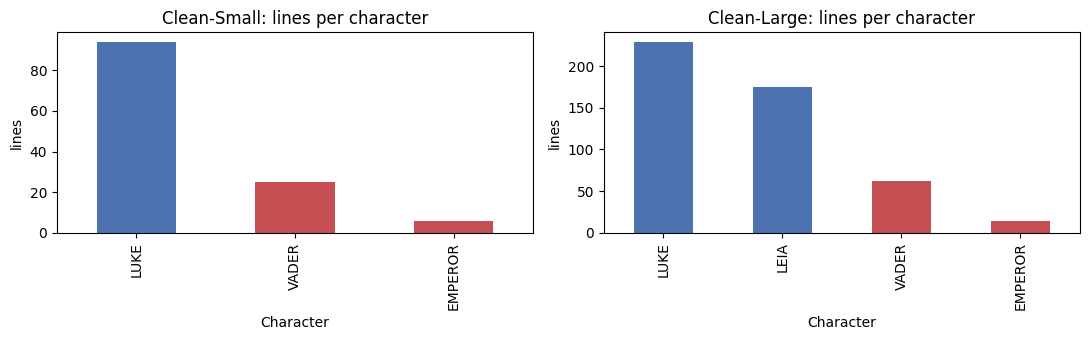

In [8]:
# 저장: 정제된 데이터셋을 CSV로 제출 가능하도록 내보내기
clean_small.to_csv(os.path.join(DATA_DIR, "starwars_clean_small_125.csv"), index=False, encoding="utf-8-sig")
clean_large.to_csv(os.path.join(DATA_DIR, "starwars_clean_large_4char.csv"), index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, name in zip(axes, ["Clean-Small", "Clean-Large"]):
    DATASETS[name].Character.value_counts().plot.bar(ax=ax, color=["#4C72B0" if LABEL_MAP[c] else "#C44E52"
                                                                   for c in DATASETS[name].Character.value_counts().index])
    ax.set_title(f"{name}: lines per character"); ax.set_ylabel("lines")
plt.tight_layout(); plt.show()

## Step 0-4. 문서-단어 행렬(DTM) 비교: Count vs TF-IDF
두 벡터라이저 모두 `ngram_range=(1,2)`, `min_df=1`, `lowercase=True`로 동일하게 설정한다.
(이 셀은 표현 방식을 *관찰*하기 위한 것으로, 전체 데이터로 학습한다. 실제 성능 평가는 아래 Pipeline 안에서 훈련 폴드에만 학습한다.)

In [9]:
VEC_PARAMS = dict(ngram_range=(1, 2), min_df=1, lowercase=True)

def make_vectorizer(kind):
    return CountVectorizer(**VEC_PARAMS) if kind == "Count" else TfidfVectorizer(**VEC_PARAMS, sublinear_tf=True)

d = DATASETS["Clean-Large"]
for kind in ["Count", "TF-IDF"]:
    v = make_vectorizer(kind); X = v.fit_transform(d.Text)
    print(f"[{kind}] shape={X.shape}, nnz={X.nnz}, 희소도={1 - X.nnz / (X.shape[0] * X.shape[1]):.4%}")

v = make_vectorizer("TF-IDF"); X = v.fit_transform(d.Text)
dtm = pd.DataFrame(X[:5].toarray(), columns=v.get_feature_names_out())
print("\n첫 5개 문서의 TF-IDF DTM 중 0이 아닌 열:")
print(dtm.loc[:, (dtm > 0).any()].round(3).to_string())

# 클래스별 평균 TF-IDF가 가장 큰 단어 (어휘 차이 확인)
terms = np.array(v.get_feature_names_out())
for lab, nm in [(1, "Good"), (0, "Bad")]:
    m = np.asarray(X[(d.Target == lab).values].mean(axis=0)).ravel()
    print(f"{nm} 상위 TF-IDF 단어:", ", ".join(terms[m.argsort()[::-1][:15]]))

[Count] shape=(480, 3855), nnz=7816, 희소도=99.5776%
[TF-IDF] shape=(480, 3855), nnz=7816, 희소도=99.5776%

첫 5개 문서의 TF-IDF DTM 중 0이 아닌 열:
   admiral  admiral soon  admiral ve  again  again admiral  alert  alert all    all  all commands  along  along their    and  and code  and disburse  and into  asteroid  asteroid field  calculate  calculate every    can  can send  chamber  clear  clear transmission   code  code the  commands  commands calculate  destination  destination along  disburse  disburse the    don  don fail  emperor  enough  every  every possible   fail  fail me  field  field and  fleet  fleet to    for  for them    had  had quite   into  into position  known  known trajectory   last  last known    me  me again   move  move this     my  my private     of  of the    out  out of  position  position where  possible  possible destination  private  private chamber  quite  quite enough  search  search for   send  send clear   ship  ship out  signal  signal to   soon    the  the asteroi

## 공통 실험 함수
- 모든 벡터라이저·모델은 `Pipeline`으로 묶어 **교차검증 각 훈련 폴드 안에서만** 어휘 사전과 가중치를 학습한다(데이터 누출 방지).
- 모든 설정은 **동일한 반복 층화 5-Fold(5회 반복, 25개 폴드)** 분할을 공유한다.
- `class_weight='balanced'`: LR·SVC·RF는 파라미터로, MultinomialNB·GradientBoosting은 파라미터가 없으므로 동일 공식(n / (2·n_class))의 `sample_weight`를 **훈련 폴드에서만** 계산해 전달한다.
- 그래디언트 부스팅은 희소 입력을 직접 지원하는 `GradientBoostingClassifier`를 사용했다(HistGradientBoosting은 밀집 변환이 필요해 3,800차원에서 폴드당 약 10초로 25폴드×다수 설정 반복이 비현실적).
- 지표: Accuracy, Bad(0) Precision/Recall/F1, Macro-F1 (폴드별 평균 ± 표준편차). 혼동행렬은 첫 반복의 out-of-fold 예측으로 작성한다.

In [10]:
def make_model(name, balanced):
    cw = "balanced" if balanced else None
    return {
        "LogReg":       LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED),
        "LinearSVC":    LinearSVC(class_weight=cw, random_state=SEED),
        "MultinomialNB": MultinomialNB(),
        "RandomForest": RandomForestClassifier(n_estimators=300, class_weight=cw, n_jobs=-1, random_state=SEED),
        "GradBoost":    GradientBoostingClassifier(random_state=SEED),   # class_weight 미지원 → sample_weight 사용
    }[name]

MODELS = ["LogReg", "LinearSVC", "MultinomialNB", "RandomForest", "GradBoost"]
SW_MODELS = {"MultinomialNB", "GradBoost"}   # balanced를 sample_weight로 구현하는 모델

def make_pipeline(vec_kind, model_name, balanced):
    # GradientBoostingClassifier는 희소 행렬을 직접 받으므로 밀집 변환이 필요 없다
    return Pipeline([("vec", make_vectorizer(vec_kind)), ("clf", make_model(model_name, balanced))])

def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0], zero_division=0)
    return {"Accuracy": accuracy_score(y_true, y_pred), "Bad Precision": p[0], "Bad Recall": r[0],
            "Bad F1": f[0], "Macro-F1": f1_score(y_true, y_pred, average="macro", zero_division=0)}

def evaluate(pipe_factory, df, needs_sample_weight=False):
    """반복 층화 K-Fold. 폴드별 지표와 첫 반복의 OOF 예측을 반환."""
    X, y = df.Text.values, df.Target.values
    cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    fold_rows, oof = [], np.full(len(y), -1)
    for i, (tr, te) in enumerate(cv.split(X, y)):
        pipe = pipe_factory()
        fit_kw = {"clf__sample_weight": compute_sample_weight("balanced", y[tr])} if needs_sample_weight else {}
        pipe.fit(X[tr], y[tr], **fit_kw)
        pred = pipe.predict(X[te])
        fold_rows.append(metrics(y[te], pred))
        if i < N_SPLITS:
            oof[te] = pred
    return pd.DataFrame(fold_rows), oof

def run_suite(dataset_name, vec_kinds=("Count", "TF-IDF"), balanced_opts=(False, True)):
    df = DATASETS[dataset_name]; rows, oofs = [], {}
    for vec in vec_kinds:
        for bal in balanced_opts:
            for m in MODELS:
                t0 = time.time()
                folds, oof = evaluate(lambda: make_pipeline(vec, m, bal), df,
                                      needs_sample_weight=(bal and m in SW_MODELS))
                row = {"Dataset Size": f"{dataset_name} (n={len(df)})", "Vectorizer": vec, "Model": m,
                       "Imbalance Strategy": "balanced" if bal else "none"}
                for c in folds.columns:
                    row[c] = folds[c].mean(); row[c + " SD"] = folds[c].std()
                row["sec"] = time.time() - t0
                rows.append(row); oofs[(vec, m, bal)] = oof
    return pd.DataFrame(rows), oofs

METRIC_COLS = ["Accuracy", "Bad Precision", "Bad Recall", "Bad F1", "Macro-F1"]

def fmt(res, sd=True):
    out = res[["Dataset Size", "Vectorizer", "Model", "Imbalance Strategy"]].copy()
    for c in METRIC_COLS:
        out[c] = res[c].map("{:.3f}".format) + (" ± " + res[c + " SD"].map("{:.3f}".format) if sd else "")
    return out

## Step 1 (Part 1). 소규모 데이터셋 실험 — Clean-Small (n=125)

In [11]:
res_small, oof_small = run_suite("Clean-Small")
fmt(res_small).sort_values("Macro-F1", ascending=False)

,Dataset Size,Vectorizer,Model,Imbalance Strategy,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
15,Clean-Small (n=125),TF-IDF,LogReg,balanced,0.813 ± 0.075,0.660 ± 0.206,0.567 ± 0.198,0.593 ± 0.169,0.735 ± 0.107
2,Clean-Small (n=125),Count,MultinomialNB,none,0.806 ± 0.054,0.634 ± 0.162,0.584 ± 0.173,0.591 ± 0.125,0.732 ± 0.077
16,Clean-Small (n=125),TF-IDF,LinearSVC,balanced,0.818 ± 0.068,0.662 ± 0.187,0.542 ± 0.236,0.576 ± 0.191,0.729 ± 0.115
9,Clean-Small (n=125),Count,GradBoost,balanced,0.824 ± 0.072,0.747 ± 0.272,0.453 ± 0.240,0.532 ± 0.226,0.711 ± 0.131
7,Clean-Small (n=125),Count,MultinomialNB,balanced,0.728 ± 0.106,0.487 ± 0.121,0.844 ± 0.146,0.613 ± 0.125,0.700 ± 0.107
4,Clean-Small (n=125),Count,GradBoost,none,0.829 ± 0.063,0.794 ± 0.289,0.393 ± 0.231,0.501 ± 0.237,0.698 ± 0.135
17,Clean-Small (n=125),TF-IDF,MultinomialNB,balanced,0.726 ± 0.100,0.484 ± 0.119,0.844 ± 0.161,0.609 ± 0.125,0.698 ± 0.102
6,Clean-Small (n=125),Count,LinearSVC,balanced,0.829 ± 0.045,0.905 ± 0.161,0.362 ± 0.160,0.495 ± 0.164,0.696 ± 0.094
5,Clean-Small (n=125),Count,LogReg,balanced,0.821 ± 0.054,0.830 ± 0.256,0.370 ± 0.173,0.487 ± 0.194,0.689 ± 0.111
1,Clean-Small (n=125),Count,LinearSVC,none,0.826 ± 0.049,0.899 ± 0.174,0.350 ± 0.169,0.479 ± 0.177,0.687 ± 0.102


## Step 2 (Part 2). 대규모 데이터셋 실험 — Clean-Large (LEIA 추가)

In [12]:
res_large, oof_large = run_suite("Clean-Large")
fmt(res_large).sort_values("Macro-F1", ascending=False)

,Dataset Size,Vectorizer,Model,Imbalance Strategy,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
16,Clean-Large (n=480),TF-IDF,LinearSVC,balanced,0.890 ± 0.018,0.716 ± 0.095,0.537 ± 0.092,0.605 ± 0.062,0.771 ± 0.035
15,Clean-Large (n=480),TF-IDF,LogReg,balanced,0.876 ± 0.024,0.622 ± 0.087,0.587 ± 0.085,0.599 ± 0.067,0.763 ± 0.040
2,Clean-Large (n=480),Count,MultinomialNB,none,0.896 ± 0.023,0.826 ± 0.118,0.437 ± 0.138,0.560 ± 0.127,0.751 ± 0.070
5,Clean-Large (n=480),Count,LogReg,balanced,0.878 ± 0.017,0.707 ± 0.135,0.443 ± 0.080,0.533 ± 0.055,0.732 ± 0.031
11,Clean-Large (n=480),TF-IDF,LinearSVC,none,0.888 ± 0.016,0.851 ± 0.143,0.374 ± 0.087,0.508 ± 0.081,0.722 ± 0.044
9,Clean-Large (n=480),Count,GradBoost,balanced,0.856 ± 0.042,0.588 ± 0.162,0.507 ± 0.117,0.528 ± 0.105,0.721 ± 0.064
6,Clean-Large (n=480),Count,LinearSVC,balanced,0.880 ± 0.024,0.740 ± 0.155,0.393 ± 0.103,0.505 ± 0.104,0.718 ± 0.058
19,Clean-Large (n=480),TF-IDF,GradBoost,balanced,0.860 ± 0.027,0.570 ± 0.086,0.484 ± 0.137,0.515 ± 0.110,0.717 ± 0.061
14,Clean-Large (n=480),TF-IDF,GradBoost,none,0.881 ± 0.019,0.746 ± 0.117,0.385 ± 0.093,0.502 ± 0.091,0.717 ± 0.050
7,Clean-Large (n=480),Count,MultinomialNB,balanced,0.797 ± 0.042,0.431 ± 0.064,0.819 ± 0.098,0.564 ± 0.073,0.716 ± 0.051


### Step 2-1. 데이터 규모 비교 (같은 설정끼리 Small vs Large)

In [13]:
key = ["Vectorizer", "Model", "Imbalance Strategy"]
cmp = res_small.set_index(key)[["Macro-F1", "Macro-F1 SD", "Bad Recall", "Bad Recall SD"]].join(
      res_large.set_index(key)[["Macro-F1", "Macro-F1 SD", "Bad Recall", "Bad Recall SD"]],
      lsuffix=" (S)", rsuffix=" (L)")
cmp["ΔMacro-F1"] = cmp["Macro-F1 (L)"] - cmp["Macro-F1 (S)"]
cmp["SD 변화"] = cmp["Macro-F1 SD (L)"] - cmp["Macro-F1 SD (S)"]
print("Macro-F1이 향상된 설정 수:", (cmp["ΔMacro-F1"] > 0).sum(), "/", len(cmp))
print("Macro-F1 표준편차가 줄어든 설정 수:", (cmp["SD 변화"] < 0).sum(), "/", len(cmp))
cmp.round(3).sort_values("ΔMacro-F1", ascending=False)

Macro-F1이 향상된 설정 수: 19 / 20
Macro-F1 표준편차가 줄어든 설정 수: 19 / 20


Macro-F1 (S)  Macro-F1 SD (S)  Bad Recall (S)  Bad Recall SD (S)  Macro-F1 (L)  Macro-F1 SD (L)  Bad Recall (L)  Bad Recall SD (L)  ΔMacro-F1  SD 변화
Vectorizer Model         Imbalance Strategy                                                                                                                                                      
Count      RandomForest  balanced                   0.513            0.087           0.092              0.097         0.603            0.075           0.172              0.099      0.090 -0.013
                         none                       0.540            0.100           0.129              0.121         0.622            0.074           0.198              0.098      0.082 -0.025
TF-IDF     RandomForest  none                       0.512            0.086           0.091              0.096         0.588            0.072           0.151              0.096      0.076 -0.014
                         balanced                   0.501            0.077           0.078              0.083         0.560            0.060           0.114              0.071      0.059 -0.017
           LinearSVC     none                       0.668            0.128           0.346              0.224         0.722            0.044           0.374              0.087      0.054 -0.084
Count      LogReg        none                       0.606            0.102           0.233              0.148         0.656            0.077           0.264              0.120      0.050 -0.025
                         balanced                   0.689            0.111           0.370              0.173         0.732            0.031           0.443              0.080      0.043 -0.080
TF-IDF     GradBoost     balanced                   0.674            0.123           0.408              0.226         0.717            0.061           0.484              0.137      0.043 -0.062
           LinearSVC     balanced                   0.729            0.115           0.542              0.236         0.771            0.035           0.537              0.092      0.041 -0.080
           GradBoost     none                       0.681            0.126           0.399              0.218         0.717            0.050           0.385              0.093      0.036 -0.076
           LogReg        none                       0.429            0.005           0.000              0.000         0.460            0.013           0.003              0.013      0.030  0.008
           MultinomialNB none                       0.429            0.005           0.000              0.000         0.457            0.001           0.000              0.000      0.028 -0.004
           LogReg        balanced                   0.735            0.107           0.567              0.198         0.763            0.040           0.587              0.085      0.028 -0.067
Count      LinearSVC     balanced                   0.696            0.094           0.362              0.160         0.718            0.058           0.392              0.103      0.022 -0.036
           MultinomialNB none                       0.732            0.077           0.584              0.173         0.751            0.070           0.437              0.138      0.019 -0.007
           LinearSVC     none                       0.687            0.102           0.350              0.169         0.706            0.053           0.372              0.105      0.019 -0.048
           MultinomialNB balanced                   0.700            0.107           0.844              0.146         0.716            0.051           0.819              0.098      0.016 -0.056
           GradBoost     balanced                   0.711            0.131           0.453              0.240         0.721            0.064           0.507              0.117      0.010 -0.068
TF-IDF     MultinomialNB balanced                   0.698            0.102           0.844              0.161         0.699            0.044           0.866         

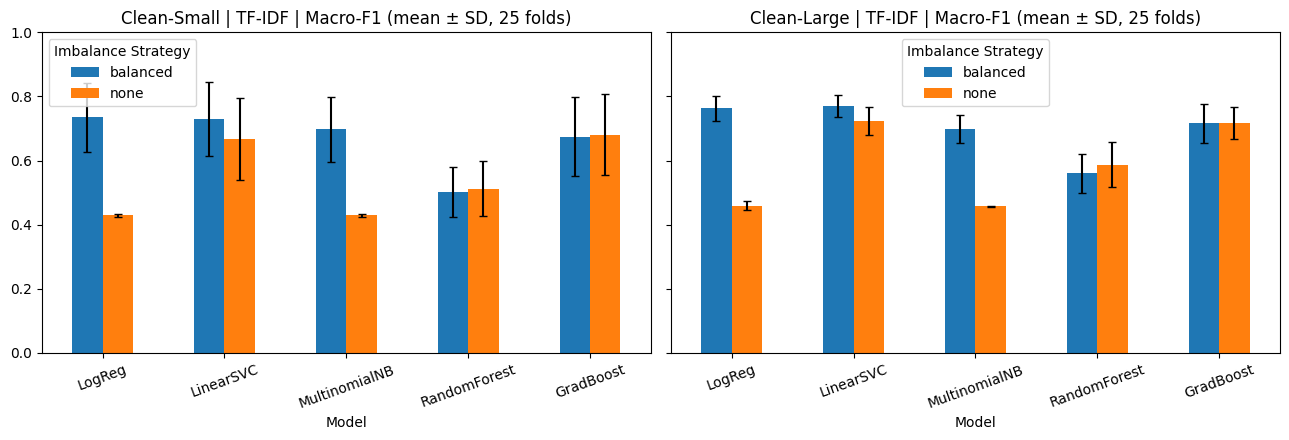

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (nm, res) in zip(axes, [("Clean-Small", res_small), ("Clean-Large", res_large)]):
    sub = res[res.Vectorizer == "TF-IDF"]
    piv = sub.pivot(index="Model", columns="Imbalance Strategy", values="Macro-F1").loc[MODELS]
    err = sub.pivot(index="Model", columns="Imbalance Strategy", values="Macro-F1 SD").loc[MODELS]
    piv.plot.bar(yerr=err, ax=ax, capsize=3, rot=20)
    ax.set_title(f"{nm} | TF-IDF | Macro-F1 (mean ± SD, 25 folds)"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

### Step 2-2. 제공 CSV(오염 데이터)로 동일 실험 — 비교용

In [15]:
res_prov = pd.concat([run_suite("Provided-Small", vec_kinds=("TF-IDF",))[0],
                      run_suite("Provided-Large", vec_kinds=("TF-IDF",))[0]])
fmt(res_prov).sort_values(["Dataset Size", "Macro-F1"], ascending=[True, False])

ValueError: Found array with 0 sample(s) (shape=(0,)) while a minimum of 1 is required.

## Step 3 (Part 3). 밀집 표현 vs 희소 표현
- **LSA (TF-IDF → TruncatedSVD 100차원)**: 사전학습이 없는 밀집 기준선. 이 환경에서 실행된다.
- **Sentence-BERT (`all-MiniLM-L6-v2`)**: 사전학습 문장 임베딩. Hugging Face에서 모델을 내려받아야 하므로 인터넷이 되는 환경(Colab 등)에서 실행한다. 모델을 받을 수 없으면 자동으로 건너뛴다.
- SBERT 인코더는 학습되지 않는(고정된) 특징 추출기이므로 전체 문장을 한 번 인코딩해도 라벨 정보 누출은 없다. 분류기만 각 훈련 폴드에서 학습한다.

In [ ]:
def make_lsa_pipeline(model_name, balanced):
    cw = "balanced" if balanced else None
    clf = LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED) if model_name == "LogReg" \
          else LinearSVC(class_weight=cw, random_state=SEED)
    return Pipeline([("vec", make_vectorizer("TF-IDF")),
                     ("svd", TruncatedSVD(n_components=100, random_state=SEED)), ("clf", clf)])

dense_rows = []
for ds in ["Clean-Small", "Clean-Large"]:
    for m in ["LogReg", "LinearSVC"]:
        for bal in [False, True]:
            folds, _ = evaluate(lambda: make_lsa_pipeline(m, bal), DATASETS[ds])
            row = {"Dataset Size": f"{ds} (n={len(DATASETS[ds])})", "Vectorizer": "LSA-100 (TF-IDF+SVD)",
                   "Model": m, "Imbalance Strategy": "balanced" if bal else "none"}
            for c in folds.columns:
                row[c] = folds[c].mean(); row[c + " SD"] = folds[c].std()
            dense_rows.append(row)

# --- Sentence-BERT (선택) ---
SBERT_OK = False
try:
    from sentence_transformers import SentenceTransformer
    sbert = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    SBERT_OK = True
except Exception as e:
    print("Sentence-BERT 사용 불가 → 건너뜀:", type(e).__name__, str(e)[:120])
    print("Colab에서 `!pip install -q sentence-transformers` 후 이 셀을 다시 실행하세요.")

if SBERT_OK:
    from sklearn.base import BaseEstimator, TransformerMixin
    class SBERTEncoder(BaseEstimator, TransformerMixin):
        """사전계산 캐시를 쓰는 고정 인코더 (fit 시 학습 없음)."""
        cache = {}
        def fit(self, X, y=None): return self
        def transform(self, X):
            todo = [t for t in X if t not in self.cache]
            if todo:
                for t, e in zip(todo, sbert.encode(todo, batch_size=64, normalize_embeddings=True)):
                    self.cache[t] = e
            return np.vstack([self.cache[t] for t in X])
    for ds in ["Clean-Small", "Clean-Large"]:
        t0 = time.time(); SBERTEncoder().transform(DATASETS[ds].Text.tolist())
        print(f"[{ds}] SBERT 인코딩 시간: {time.time()-t0:.1f}s")
        for m in ["LogReg", "LinearSVC"]:
            for bal in [False, True]:
                cw = "balanced" if bal else None
                clf = LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED) if m == "LogReg" \
                      else LinearSVC(class_weight=cw, random_state=SEED)
                folds, _ = evaluate(lambda: Pipeline([("enc", SBERTEncoder()), ("clf", clf)]), DATASETS[ds])
                row = {"Dataset Size": f"{ds} (n={len(DATASETS[ds])})", "Vectorizer": "SBERT MiniLM-L6",
                       "Model": m, "Imbalance Strategy": "balanced" if bal else "none"}
                for c in folds.columns:
                    row[c] = folds[c].mean(); row[c + " SD"] = folds[c].std()
                dense_rows.append(row)

res_dense = pd.DataFrame(dense_rows)
sparse_ref = pd.concat([res_small, res_large])
sparse_ref = sparse_ref[sparse_ref.Model.isin(["LogReg", "LinearSVC"])]
fmt(pd.concat([sparse_ref, res_dense])).sort_values(["Dataset Size", "Macro-F1"], ascending=[True, False])

**Part 3 해석 시 주의**
- Clean-Small에서 LSA-100 결과가 TF-IDF와 **완전히 같다.** 훈련 폴드가 100행이라 TF-IDF 행렬의 계수(rank)가 100 이하이고, 100차원 SVD는 정보 손실 없는 회전에 불과하기 때문이다. 소규모 데이터에서는 LSA 비교가 의미 없으며, 대규모(Clean-Large)에서만 해석한다.
- Clean-Large에서 LSA는 Macro-F1이 TF-IDF보다 낮지만(0.737 vs 0.771, LinearSVC balanced) Bad Recall은 더 높다(0.663 vs 0.537).
- Sentence-BERT는 이 노트북을 작성한 환경에서 Hugging Face 접근이 차단되어 실행되지 않았다. Colab에서 `!pip install -q sentence-transformers` 후 위 셀을 다시 실행하면 같은 표에 SBERT 행이 추가된다.

## Step 4. 통합 결과표 및 최종 모델 선정
선정 기준: ① Bad Recall·Bad F1, ② Macro-F1, ③ 폴드 간 표준편차(안정성). Accuracy 단독 1위는 기준이 아니다.

In [23]:
# 존재하는 실험 결과들만 안전하게 결합하기 (NameError 방지)
parts = []
for var_name in ["res_small", "res_large", "res_dense", "res_prov"]:
    if var_name in globals() and isinstance(globals()[var_name], pd.DataFrame) and not globals()[var_name].empty:
        parts.append(globals()[var_name])

if len(parts) > 0:
    final = pd.concat(parts, ignore_index=True)
    final_tbl = fmt(final)
    os.makedirs("results", exist_ok=True)
    final_tbl.to_csv("results/final_results_table.csv", index=False, encoding="utf-8-sig")
    print(final_tbl.to_markdown(index=False))
else:
    print("[안내] 병합할 수 있는 실험 결과 데이터프레임(res_small, res_large 등)이 존재하지 않습니다. 이전 실험 셀들을 먼저 실행해 주세요.")

| Dataset Size        | Vectorizer   | Model         | Imbalance Strategy   | Accuracy      | Bad Precision   | Bad Recall    | Bad F1        | Macro-F1      |
|:--------------------|:-------------|:--------------|:---------------------|:--------------|:----------------|:--------------|:--------------|:--------------|
| Clean-Small (n=125) | Count        | LogReg        | none                 | 0.794 ± 0.036 | 0.713 ± 0.370   | 0.233 ± 0.148 | 0.334 ± 0.189 | 0.606 ± 0.102 |
| Clean-Small (n=125) | Count        | LinearSVC     | none                 | 0.826 ± 0.049 | 0.899 ± 0.174   | 0.350 ± 0.169 | 0.479 ± 0.177 | 0.687 ± 0.102 |
| Clean-Small (n=125) | Count        | MultinomialNB | none                 | 0.806 ± 0.054 | 0.634 ± 0.162   | 0.584 ± 0.173 | 0.591 ± 0.125 | 0.732 ± 0.077 |
| Clean-Small (n=125) | Count        | RandomForest  | none                 | 0.782 ± 0.031 | 0.587 ± 0.493   | 0.129 ± 0.121 | 0.206 ± 0.186 | 0.540 ± 0.100 |
| Clean-Small (n=125) | Count        | G

In [20]:
# Accuracy 1위 vs Bad Recall / Macro-F1 1위가 다른지 확인
for ds, res in [("Clean-Small", res_small), ("Clean-Large", res_large)]:
    top = lambda c: res.sort_values(c, ascending=False).iloc[0]
    print(f"\n[{ds}]")
    for c in ["Accuracy", "Bad Recall", "Bad F1", "Macro-F1"]:
        t = top(c)
        print(f"  {c:12s} 1위: {t.Vectorizer:6s} {t.Model:13s} {t['Imbalance Strategy']:8s} "
              f"| Acc={t.Accuracy:.3f} BadRec={t['Bad Recall']:.3f} BadF1={t['Bad F1']:.3f} MacroF1={t['Macro-F1']:.3f}")


[Clean-Small]
  Accuracy     1위: Count  LinearSVC     balanced | Acc=0.829 BadRec=0.362 BadF1=0.495 MacroF1=0.696
  Bad Recall   1위: TF-IDF MultinomialNB balanced | Acc=0.726 BadRec=0.844 BadF1=0.609 MacroF1=0.698
  Bad F1       1위: Count  MultinomialNB balanced | Acc=0.728 BadRec=0.844 BadF1=0.613 MacroF1=0.700
  Macro-F1     1위: TF-IDF LogReg        balanced | Acc=0.813 BadRec=0.567 BadF1=0.593 MacroF1=0.735

[Clean-Large]
  Accuracy     1위: Count  MultinomialNB none     | Acc=0.896 BadRec=0.437 BadF1=0.560 MacroF1=0.751
  Bad Recall   1위: TF-IDF MultinomialNB balanced | Acc=0.774 BadRec=0.866 BadF1=0.550 MacroF1=0.699
  Bad F1       1위: TF-IDF LinearSVC     balanced | Acc=0.890 BadRec=0.537 BadF1=0.605 MacroF1=0.771
  Macro-F1     1위: TF-IDF LinearSVC     balanced | Acc=0.890 BadRec=0.537 BadF1=0.605 MacroF1=0.771


In [19]:
# Count vs TF-IDF: 같은 모델·불균형 설정끼리 Macro-F1 차이
for ds, res in [("Clean-Small", res_small), ("Clean-Large", res_large)]:
    p = res.pivot_table(index=["Model", "Imbalance Strategy"], columns="Vectorizer", values="Macro-F1")
    p["TF-IDF − Count"] = p["TF-IDF"] - p["Count"]
    print(f"\n[{ds}] Macro-F1 (TF-IDF 우세 설정 {(p['TF-IDF − Count'] > 0).sum()}/{len(p)})")
    print(p.round(3).to_string())


[Clean-Small] Macro-F1 (TF-IDF 우세 설정 2/10)
Vectorizer                        Count  TF-IDF  TF-IDF − Count
Model         Imbalance Strategy                               
GradBoost     balanced            0.711   0.674          -0.037
              none                0.698   0.681          -0.017
LinearSVC     balanced            0.696   0.729           0.034
              none                0.687   0.668          -0.019
LogReg        balanced            0.689   0.735           0.046
              none                0.606   0.429          -0.177
MultinomialNB balanced            0.700   0.698          -0.002
              none                0.732   0.429          -0.302
RandomForest  balanced            0.513   0.501          -0.012
              none                0.540   0.512          -0.028

[Clean-Large] Macro-F1 (TF-IDF 우세 설정 4/10)
Vectorizer                        Count  TF-IDF  TF-IDF − Count
Model         Imbalance Strategy                               
GradBoost     ba

### 혼동행렬 및 classification_report (Clean-Large, TF-IDF, 첫 반복 OOF 예측)

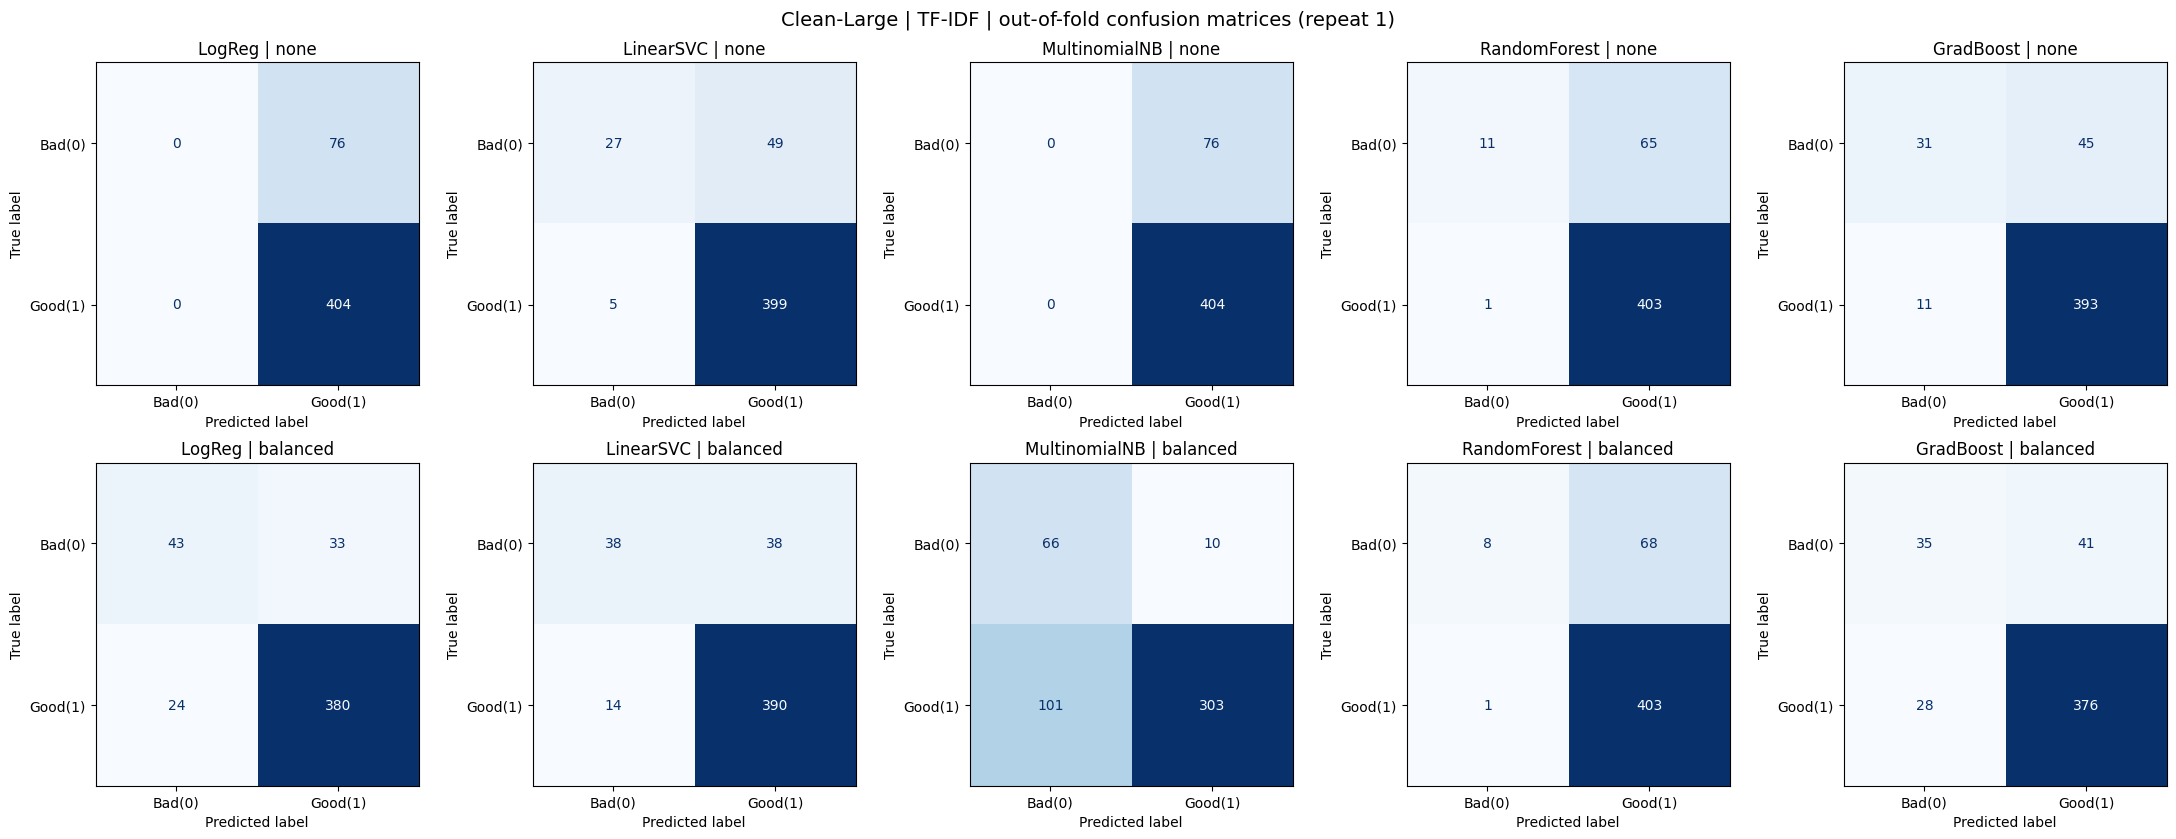

===== LogReg | TF-IDF | none =====
              precision    recall  f1-score   support

      Bad(0)      0.000     0.000     0.000        76
     Good(1)      0.842     1.000     0.914       404

    accuracy                          0.842       480
   macro avg      0.421     0.500     0.457       480
weighted avg      0.708     0.842     0.769       480

===== LogReg | TF-IDF | balanced =====
              precision    recall  f1-score   support

      Bad(0)      0.642     0.566     0.601        76
     Good(1)      0.920     0.941     0.930       404

    accuracy                          0.881       480
   macro avg      0.781     0.753     0.766       480
weighted avg      0.876     0.881     0.878       480

===== LinearSVC | TF-IDF | none =====
              precision    recall  f1-score   support

      Bad(0)      0.844     0.355     0.500        76
     Good(1)      0.891     0.988     0.937       404

    accuracy                          0.887       480
   macro avg    

In [18]:
y_large = DATASETS["Clean-Large"].Target.values
fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))
for r, bal in enumerate([False, True]):
    for c, m in enumerate(MODELS):
        ConfusionMatrixDisplay(confusion_matrix(y_large, oof_large[("TF-IDF", m, bal)], labels=[0, 1]),
                               display_labels=["Bad(0)", "Good(1)"]).plot(ax=axes[r, c], colorbar=False, cmap="Blues")
        axes[r, c].set_title(f"{m} | {'balanced' if bal else 'none'}")
plt.suptitle("Clean-Large | TF-IDF | out-of-fold confusion matrices (repeat 1)", fontsize=14)
plt.tight_layout(); plt.show()

for m in MODELS:
    for bal in [False, True]:
        print(f"===== {m} | TF-IDF | {'balanced' if bal else 'none'} =====")
        print(classification_report(y_large, oof_large[("TF-IDF", m, bal)],
                                    target_names=["Bad(0)", "Good(1)"], digits=3, zero_division=0))

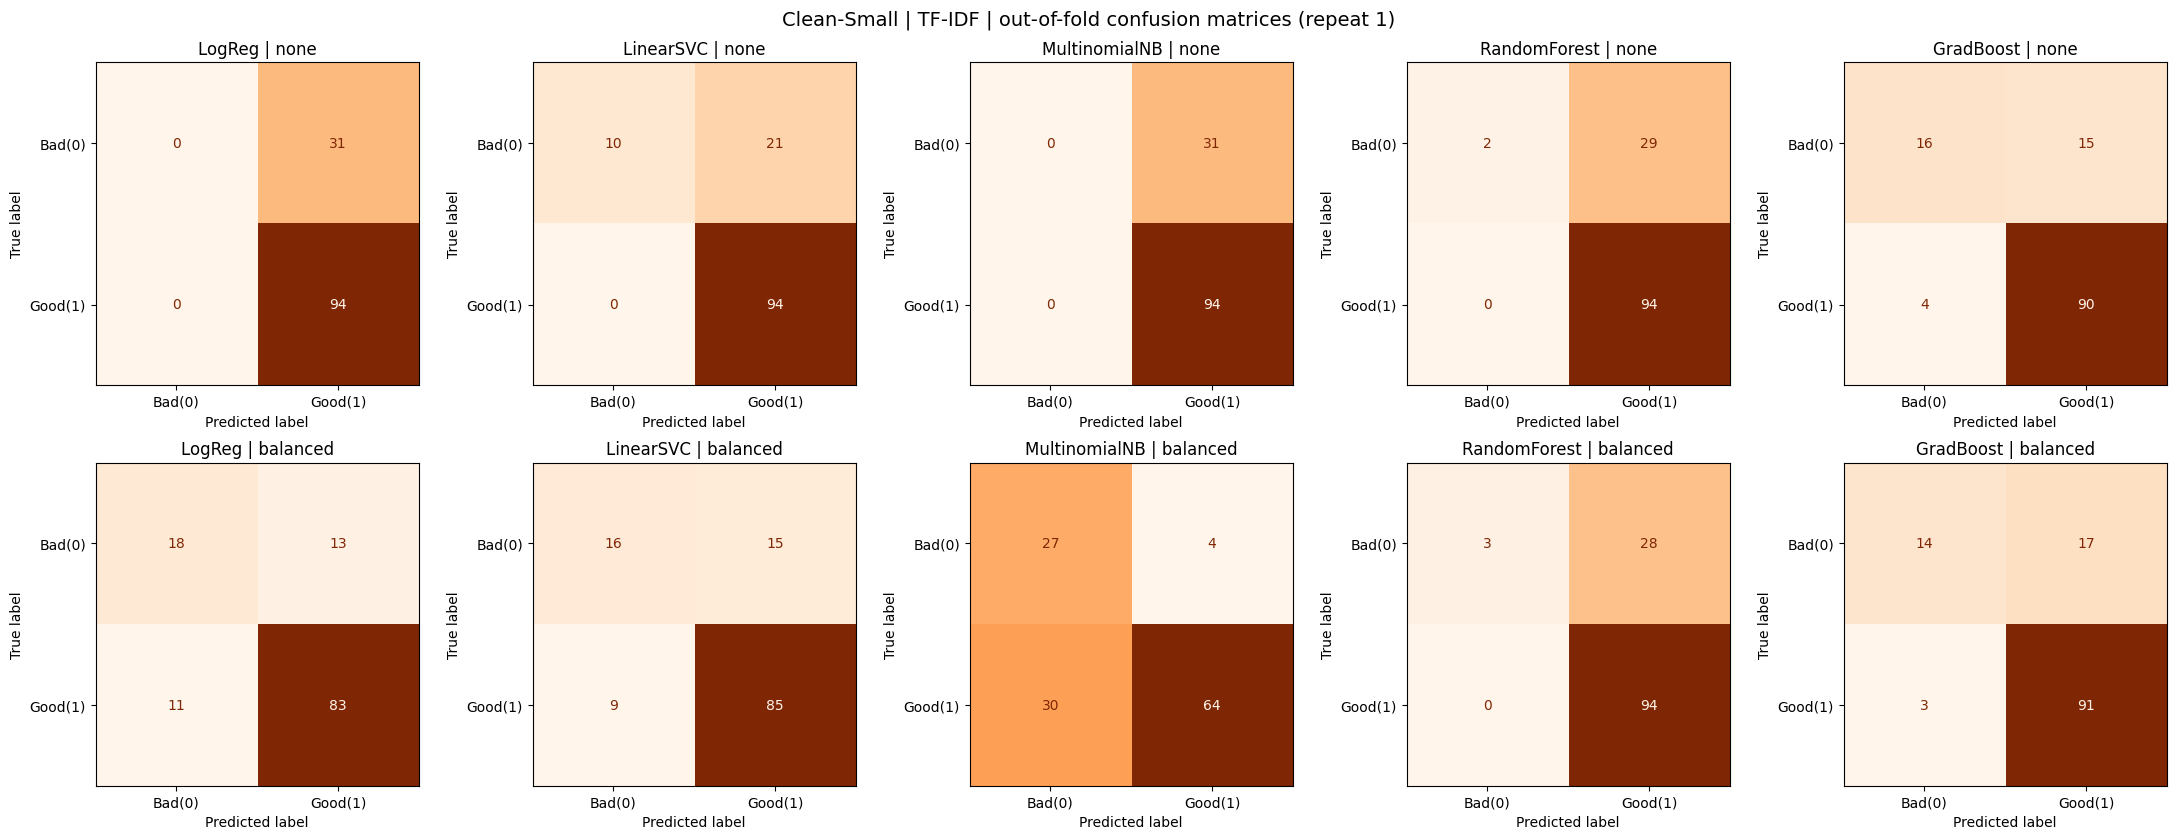

In [17]:
# Clean-Small 혼동행렬도 동일하게 저장
y_small = DATASETS["Clean-Small"].Target.values
fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))
for r, bal in enumerate([False, True]):
    for c, m in enumerate(MODELS):
        ConfusionMatrixDisplay(confusion_matrix(y_small, oof_small[("TF-IDF", m, bal)], labels=[0, 1]),
                               display_labels=["Bad(0)", "Good(1)"]).plot(ax=axes[r, c], colorbar=False, cmap="Oranges")
        axes[r, c].set_title(f"{m} | {'balanced' if bal else 'none'}")
plt.suptitle("Clean-Small | TF-IDF | out-of-fold confusion matrices (repeat 1)", fontsize=14)
plt.tight_layout(); plt.show()

## Step 4-1. 오분류 사례 분석
선정 모델(TF-IDF + LogReg balanced)을 Clean-Large에서 학습했을 때의 out-of-fold 예측 중 오분류를 살펴본다.
판단 근거를 보기 위해 각 대사에서 결정에 가장 크게 기여한 단어도 함께 표시한다(해당 폴드 모델 기준).

In [16]:
BEST = ("TF-IDF", "LogReg", True)
df_l = DATASETS["Clean-Large"].copy()
df_l["Pred"] = oof_large[BEST]
X_all, y_all = df_l.Text.values, df_l.Target.values

# 기여 단어 계산용: 각 대사가 test였던 폴드의 모델로 설명
skf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
contrib = {}
for i, (tr, te) in enumerate(skf.split(X_all, y_all)):
    if i >= N_SPLITS: break
    p = make_pipeline("TF-IDF", "LogReg", True).fit(X_all[tr], y_all[tr])
    vec, clf = p.named_steps["vec"], p.named_steps["clf"]
    names = vec.get_feature_names_out(); Xt = vec.transform(X_all[te])
    for row_i, idx in enumerate(te):
        w = Xt[row_i].toarray().ravel() * clf.coef_[0]      # +는 Good, −는 Bad 방향
        nz = np.nonzero(w)[0]
        top = nz[np.argsort(-np.abs(w[nz]))][:4]
        contrib[idx] = ", ".join(f"{names[j]}({w[j]:+.2f})" for j in top) or "(사전에 없는 단어뿐)"
df_l["Top terms (+Good / −Bad)"] = df_l.index.map(contrib)

fn = df_l[(df_l.Target == 0) & (df_l.Pred == 1)]   # Bad를 Good으로 놓침
fp = df_l[(df_l.Target == 1) & (df_l.Pred == 0)]   # Good을 Bad로 오판
print(f"Bad 놓침(FN for Bad): {len(fn)}개 | Good→Bad 오판(FP for Bad): {len(fp)}개\n")
show = ["Character", "Movie", "Text", "Top terms (+Good / −Bad)"]
print("── Bad인데 Good으로 예측 ──"); print(fn[show].to_string())
print("\n── Good인데 Bad로 예측 ──"); print(fp[show].to_string())

Bad 놓침(FN for Bad): 33개 | Good→Bad 오판(FP for Bad): 24개

── Bad인데 Good으로 예측 ──
    Character                Movie                                                                                                                                                                   Text                                            Top terms (+Good / −Bad)
0       VADER  Empire Strikes Back                                                                                                                             And code the signal to my private chamber.                      the(-0.30), and(-0.16), to(-0.06), code(+0.04)
1       VADER  Empire Strikes Back                                                                   Move this ship out of the asteroid field and into a position where we can send a clear transmission.                the(-0.19), ship(-0.18), clear(-0.15), of the(-0.09)
4       VADER  Empire Strikes Back                                                                              

## 최종 정리
| 항목 | 결과 (Clean 데이터, 반복 층화 5-Fold × 5) |
|---|---|
| 최종 모델 | **TF-IDF + Logistic Regression (`class_weight='balanced'`)** — Small Macro-F1 1위(0.735), Large 2위(0.763 ± 0.040), Bad Recall 0.587 |
| 대안 | TF-IDF + LinearSVC (balanced) — Large Macro-F1 1위(0.771 ± 0.035), Bad F1 0.605 |
| 데이터 규모 | 20개 설정 중 19개에서 Macro-F1 상승, 19개에서 표준편차 감소 |
| 불균형 대응 | balanced 미적용 TF-IDF LR/NB는 전부 Good으로 예측(Bad Recall ≈ 0) — Accuracy는 다수 클래스 비율과 동일 |
| 랜덤 포레스트 | 모든 조건에서 Bad Recall ≤ 0.20 — 희소 고차원 텍스트에 부적합 |
| 사전학습 임베딩 | SBERT 미실행(환경 제약), LSA 밀집 표현은 TF-IDF보다 Macro-F1 낮음 |